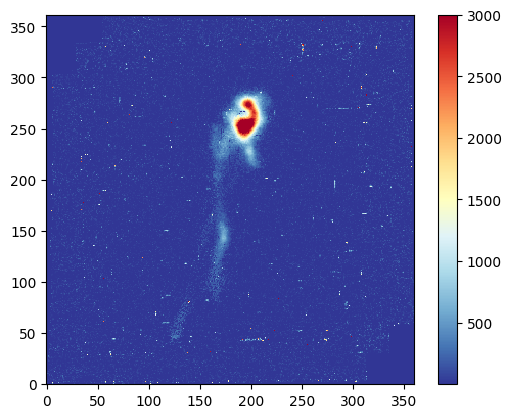

/var/folders/8w/t9k3qcps0t7c124t1sl5wvh40000gn/T/ipykernel_88759/4252683846.py:118: RuntimeWarning: invalid value encountered in divide
  mask = NII6583_flux.data/NII6583_flux.data


In [23]:
from astropy.io import fits
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LogNorm

from astropy import units as u
from astropy import constants as const
import astropy.constants as const
from astropy.convolution import convolve,Gaussian2DKernel
from mpdaf.obj import Image
import astropy.units as u
import pyregion
import pyregion._region_filter as filter
from pyregion import read_region_as_imagecoord, get_mask



import matplotlib as mpl
# Properties of the plots
import matplotlib as mpl


# Read in the WCS from the data cube,
# so that we can directly paste it into the
# maps we're making

########## EDIT STUFF HERE ################


#z = 0.01093
#cz = z * const.c.to('km/s')
c =  const.c.to('km/s')
id='A1795'
gas = 'res_cube_'+id+'.fits'


#############################################
##### MAKE GAS

# Read in the emission line table, from which we'll make gas maps
eline_hdu = fits.open(gas)
eline_tab = eline_hdu[1].data
eline_columns = eline_hdu[1].header

eline_x_cor = eline_hdu['X']
eline_y_cor = eline_hdu['Y']

Z = eline_hdu['Z']

Ha_flux = eline_hdu['H_ALPHA_FLUX']
Ha_flux_err = eline_hdu['H_ALPHA_FLUX_ERR']
Ha_vel = eline_hdu['V_OFF_BALMER']
Ha_vel_err = eline_hdu['V_OFF_BALMER_ERR']
Ha_fwhm = eline_hdu['SIGMA_BALMER']
Ha_fwhm_err = eline_hdu['SIGMA_BALMER_ERR']

NII6583_flux = eline_hdu['NII_6584_FLUX'] 
NII6583_flux_err = eline_hdu['NII_6584_FLUX_ERR'] 


z_stars = Z.data
z_mean = 0.0633

delta_velo = (z_stars - z_mean) * c.value
where_are_NaNs = np.isnan(delta_velo)
delta_velo[where_are_NaNs] = 0

Ha_vel.data = (Ha_vel.data + delta_velo) + 150
plt.imshow(NII6583_flux.data,origin='lower',cmap='RdYlBu_r',vmin=0.1,vmax=3000,interpolation='nearest')
plt.colorbar()
plt.show()


# NII
gas_select = (Ha_flux.data > 250000)
vel_noselect = (Ha_vel.data > 200.0)
vel_noselect_neg = (Ha_vel.data < -400.0)
fwhm_noselect =  (Ha_fwhm.data > 500.0)
fwhm_noselect_ned =  (Ha_fwhm.data < 40.0)
NII6583_flux.data[Ha_fwhm_err.data>4] = np.nan

NII6583_flux.data[Ha_vel_err.data>4] = np.nan
NII6583_flux.data[NII6583_flux_err.data<4] = np.nan

Ha_vel.data[Ha_vel_err.data>4] = np.nan
Ha_vel_err.data[Ha_vel_err.data>4] = np.nan

NII6583_flux.data[gas_select] = np.nan
NII6583_flux.data[fwhm_noselect] = np.nan

Ha_vel.data[gas_select] = np.nan
Ha_vel.data[fwhm_noselect] = np.nan
Ha_vel.data[vel_noselect] = np.nan
Ha_vel.data[vel_noselect_neg] = np.nan


Ha_fwhm.data[gas_select] = np.nan
Ha_fwhm.data[fwhm_noselect] = np.nan
Ha_fwhm.data[vel_noselect] = np.nan
Ha_fwhm.data[vel_noselect_neg] = np.nan

# Convolution NII
NII6583_flux.data = convolve(NII6583_flux.data, Gaussian2DKernel(1.5,1.5))                    
NII6583_flux.data[NII6583_flux.data<20] = np.nan
NII6583_flux.data[0:360,0:100]=np.nan
NII6583_flux.data[0:360,280:360]=np.nan
NII6583_flux.data[300:360,0:360]=np.nan
NII6583_flux.data[0:80,180:300]=np.nan


r = pyregion.open('region.fits')
          
# Creating the mask
mymask = r.get_mask(hdu=eline_hdu[1],shape=(362, 360))
NII6583_flux.data= NII6583_flux.data * mymask
mask = NII6583_flux.data/NII6583_flux.data


# Delete the borders

#plt.imshow(NII6583_flux.data*mask,origin='lower',cmap='RdYlBu_r',vmin=0.1,vmax=3000,interpolation='nearest')
#plt.colorbar()
#plt.show()
# Mask
#mask = NII6583_flux.data/NII6583_flux.data


from astropy.utils.data import get_pkg_data_filename
from astropy.wcs import WCS
from astropy import wcs

def save_line(data,filename):
    hdr = Z.header
    hdu = fits.PrimaryHDU(data)
    hdu.header = hdr
   # CRVAL1  = 207.2191
   # CRVAL2  = 26.58862
    CRVAL1 = 207.21925
    CRVAL2 = 26.58872

    hdr['CRVAL1']=CRVAL1
    hdr['CRVAL2']=CRVAL2

    hdu.writeto(filename,overwrite=True,output_verify='silentfix')

    museHDU = fits.open(filename)
    museHDU.info()
    w_muse = WCS(museHDU[0])
    w_muse = wcs.WCS(museHDU[0])
    muse_3wcs = w_muse.dropaxis(2)
    w_muse = muse_3wcs
    newmuseHeader = w_muse.to_header()
    fits.writeto(filename, museHDU[0].data, newmuseHeader,overwrite=True)

def make_line(line,line_err):
    ######## 

    gas_select = (Ha_flux.data > 250000)
    vel_noselect = (Ha_vel.data > 300.0)
    vel_noselect_neg = (Ha_vel.data < -400.0)
    fwhm_noselect =  (Ha_fwhm.data > 500.0)
    fwhm_noselect_ned =  (Ha_fwhm.data < 40.0)

    line.data[NII6583_flux.data==np.nan] = np.nan
    line.data[Ha_vel_err.data>6] = np.nan
    line.data[Ha_fwhm_err.data>6] = np.nan
    line.data[line_err.data<3] = np.nan

    line.data[gas_select] = np.nan
    line.data[fwhm_noselect] = np.nan
    line.data[vel_noselect] = np.nan
    line.data[vel_noselect_neg] = np.nan
    
    line.data[line.data<20.0] = np.nan
    return line



In [11]:

line.data = convolve(line.data*mask, Gaussian2DKernel(0.14,0.14))  
line.data[line.data<70]=np.nan
line.data[np.isnan(data*mask)] = np.nan
    
plt.imshow(data,cmap='RdYlBu_r',vmin=0,vmax=3000,origin='lower',interpolation='nearest')
plt.colorbar()
plt.show()



NameError: name 'data' is not defined

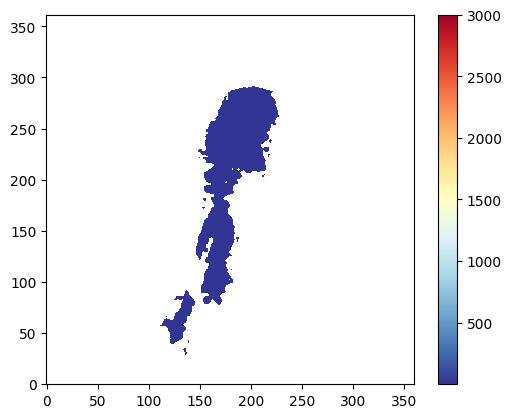

In [24]:
plt.imshow(mask,origin='lower',cmap='RdYlBu_r',vmin=0.1,vmax=3000,interpolation='nearest')
plt.colorbar()
plt.show()


Filename: SII_6717_FLUX_noclean.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  Z             1 PrimaryHDU      34   (360, 362)   float32   


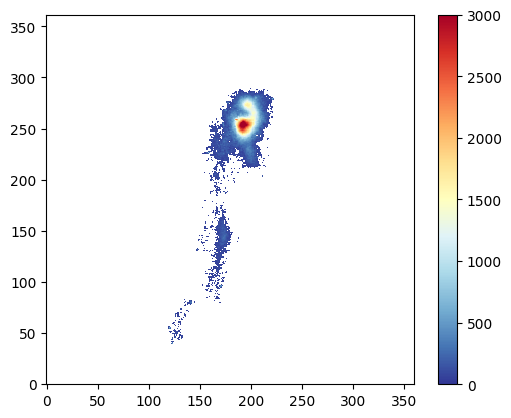

Filename: SII_6717_FLUX.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  Z             1 PrimaryHDU      34   (360, 362)   float32   
Filename: SII_6717_FLUX_ERR.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  Z             1 PrimaryHDU      34   (360, 362)   float32   


Filename: SII_6731_FLUX_noclean.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  Z             1 PrimaryHDU      34   (360, 362)   float32   


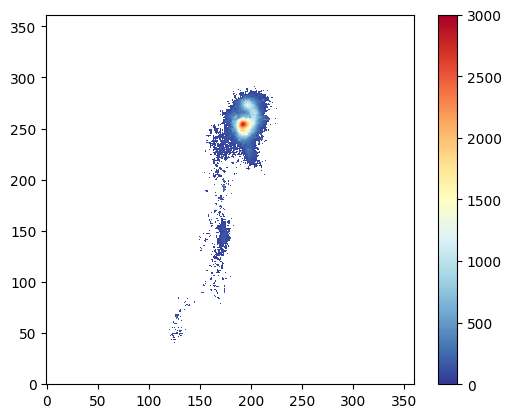

Filename: SII_6731_FLUX.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  Z             1 PrimaryHDU      34   (360, 362)   float32   
Filename: SII_6731_FLUX_ERR.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  Z             1 PrimaryHDU      34   (360, 362)   float32   


Filename: NII_6584_FLUX_noclean.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  Z             1 PrimaryHDU      34   (360, 362)   float32   


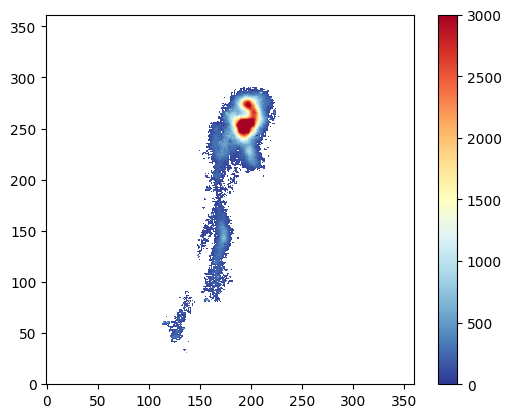

Filename: NII_6584_FLUX.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  Z             1 PrimaryHDU      34   (360, 362)   float32   
Filename: NII_6584_FLUX_ERR.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  Z             1 PrimaryHDU      34   (360, 362)   float32   


Filename: NII_6548_FLUX_noclean.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  Z             1 PrimaryHDU      34   (360, 362)   float32   


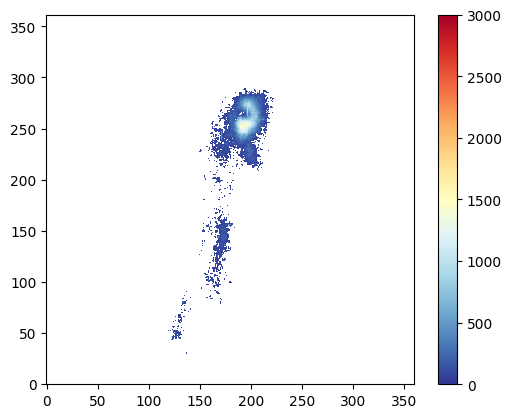

Filename: NII_6548_FLUX.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  Z             1 PrimaryHDU      34   (360, 362)   float32   
Filename: NII_6548_FLUX_ERR.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  Z             1 PrimaryHDU      34   (360, 362)   float32   


Filename: NII_5755_FLUX.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  Z             1 PrimaryHDU      34   (360, 362)   float32   
Filename: NII_5755_FLUX_ERR.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  Z             1 PrimaryHDU      34   (360, 362)   float32   


Filename: H_BETA_FLUX_noclean.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  Z             1 PrimaryHDU      34   (360, 362)   float32   


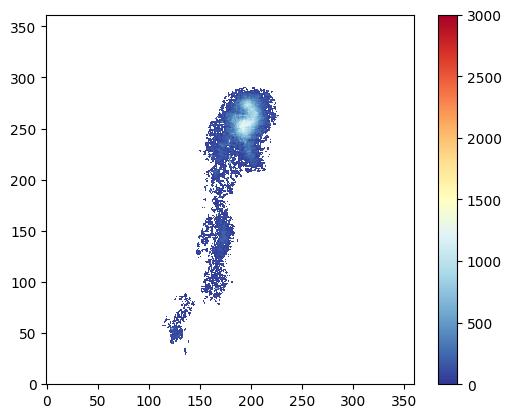

Filename: H_BETA_FLUX.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  Z             1 PrimaryHDU      34   (360, 362)   float32   
Filename: H_BETA_FLUX_ERR.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  Z             1 PrimaryHDU      34   (360, 362)   float32   


Filename: OIII_4959_FLUX_noclean.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  Z             1 PrimaryHDU      34   (360, 362)   float32   


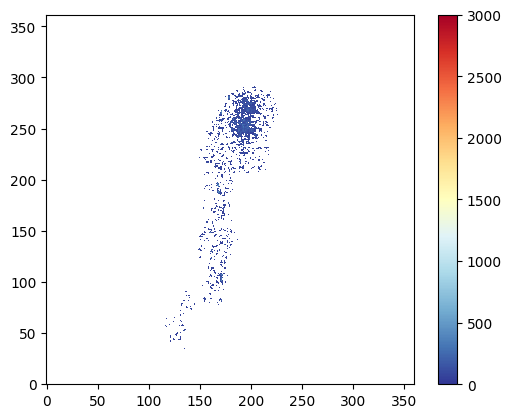

Filename: OIII_4959_FLUX.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  Z             1 PrimaryHDU      34   (360, 362)   float32   
Filename: OIII_4959_FLUX_ERR.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  Z             1 PrimaryHDU      34   (360, 362)   float32   


Filename: OIII_5007_FLUX_noclean.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  Z             1 PrimaryHDU      34   (360, 362)   float32   


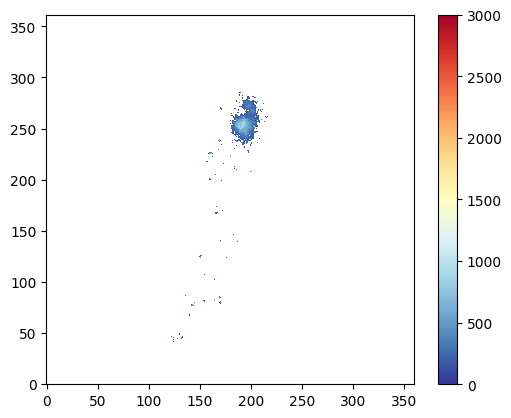

Filename: OIII_5007_FLUX.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  Z             1 PrimaryHDU      34   (360, 362)   float32   
Filename: OIII_5007_FLUX_ERR.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  Z             1 PrimaryHDU      34   (360, 362)   float32   


Filename: OI_6300_FLUX_noclean.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  Z             1 PrimaryHDU      34   (360, 362)   float32   


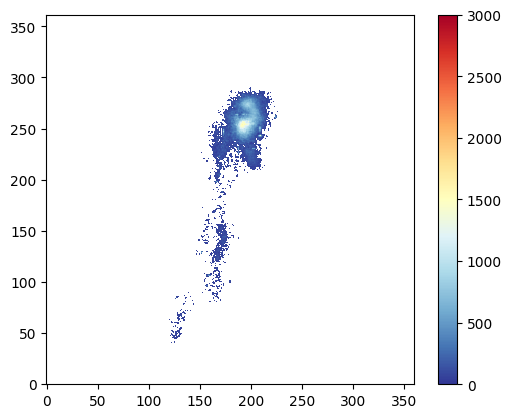

Filename: OI_6300_FLUX.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  Z             1 PrimaryHDU      34   (360, 362)   float32   
Filename: OI_6300_FLUX_ERR.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  Z             1 PrimaryHDU      34   (360, 362)   float32   


Filename: H_ALPHA_FLUX_noclean.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  Z             1 PrimaryHDU      34   (360, 362)   float32   


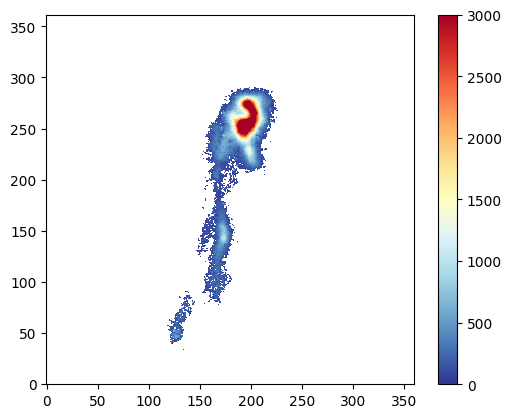

Filename: H_ALPHA_FLUX.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  Z             1 PrimaryHDU      34   (360, 362)   float32   
Filename: H_ALPHA_FLUX_ERR.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  Z             1 PrimaryHDU      34   (360, 362)   float32   


Filename: ARIII7135_FLUX_noclean.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  Z             1 PrimaryHDU      34   (360, 362)   float32   


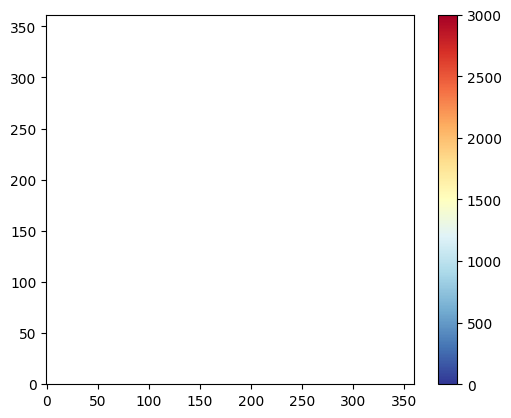

Filename: ARIII7135_FLUX.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  Z             1 PrimaryHDU      34   (360, 362)   float32   
Filename: ARIII7135_FLUX_ERR.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  Z             1 PrimaryHDU      34   (360, 362)   float32   


Filename: NI_5199_FLUX.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  Z             1 PrimaryHDU      34   (360, 362)   float32   
Filename: NI_5199_FLUX_ERR.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  Z             1 PrimaryHDU      34   (360, 362)   float32   


Filename: HEI_5876_FLUX_noclean.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  Z             1 PrimaryHDU      34   (360, 362)   float32   


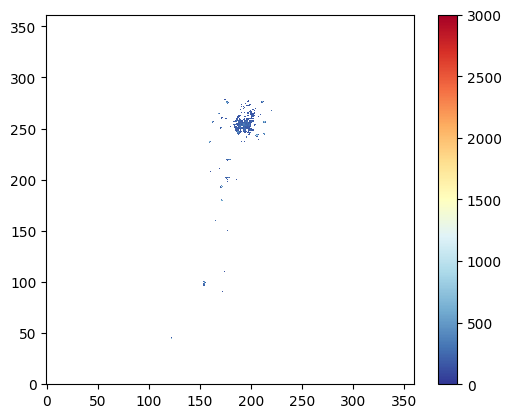

Filename: HEI_5876_FLUX.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  Z             1 PrimaryHDU      34   (360, 362)   float32   


Filename: HEI_5876_FLUX_ERR.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  Z             1 PrimaryHDU      34   (360, 362)   float32   


In [36]:


def make_line(line):
  #  line.data[gas_select] = np.nan
    #line.data[fwhm_noselect] = np.nan
    line.data[0:360,0:100]=np.nan
    line.data[0:360,280:360]=np.nan
    line.data[300:360,0:360]=np.nan
    line.data[0:80,180:300]=np.nan

    line.data[Ha_vel_err.data==0] = np.nan
    line.data[Ha_vel_err.data>4] = np.nan


    return line

def make_line_err(line):
    line.data[0:360,0:100]=np.nan
    line.data[0:360,280:360]=np.nan
    line.data[300:360,0:360]=np.nan
    line.data[0:80,180:300]=np.nan

    return line

lines = ['SII_6717_FLUX','SII_6731_FLUX','NII_6584_FLUX',
        'NII_6548_FLUX','NII_5755_FLUX','H_BETA_FLUX','OIII_4959_FLUX','OIII_5007_FLUX',
        'OI_6300_FLUX','H_ALPHA_FLUX','ARIII7135_FLUX','NI_5199_FLUX','HEI_5876_FLUX',
         ]

lines_err = ['SII_6717_FLUX_ERR','SII_6731_FLUX_ERR','NII_6584_FLUX_ERR',
        'NII_6548_FLUX_ERR','NII_5755_FLUX_ERR','H_BETA_FLUX_ERR','OIII_4959_FLUX_ERR','OIII_5007_FLUX_ERR',
            'OI_6300_FLUX_ERR','H_ALPHA_FLUX_ERR','ARIII7135_FLUX_ERR','NI_5199_FLUX_ERR','HEI_5876_FLUX_ERR',
            ]

for i,j in zip(lines,lines_err):
    try:
        id='A1795'
        gas = 'res_cube_'+id+'.fits'
        eline_hdu = fits.open(gas)

        line = eline_hdu[i]
        line_err = eline_hdu[j]

        # s/n > 3
        line.data[Ha_vel_err.data>3.5] = np.nan
        line.data[Ha_fwhm_err.data>5.0] = np.nan
        line.data[line.data<0] = np.nan

        line.data = convolve(line.data, Gaussian2DKernel(0.2,0.2))    


        line.data[line.data<0] = np.nan

        save_line(line.data,i+'_noclean.fits')
        ####################
        id='A1795'
        gas = 'res_cube_'+id+'.fits'
        eline_hdu = fits.open(gas)

        line = eline_hdu[i]
        line_err = eline_hdu[j]

        line=make_line(line)
        line_err=make_line(line_err)

        line.data[Ha_vel_err.data>3.5] = np.nan
        line.data[Ha_fwhm_err.data>5.5] = np.nan


        line.data[0:360,0:100]=np.nan
        line.data[0:360,280:360]=np.nan
        line.data[300:360,0:360]=np.nan
        line.data[0:80,180:300]=np.nan

        line.data = convolve(line.data, Gaussian2DKernel(0.5,0.5))                    

        if i== 'H_BETA_FLUX':
            line.data[line.data<20]=np.nan
        elif i== 'OIII_4959_FLUX':
            line.data[line.data<50]=np.nan

        elif i== 'OIII_5007_FLUX' or i=='HEI_5876_FLUX':
            line.data[line.data<150]=np.nan
        else:
            line.data[line.data<50]=np.nan

        plt.imshow(line.data*mask,cmap='RdYlBu_r',vmin=0,vmax=3000,origin='lower',interpolation='nearest')
        plt.colorbar()
        plt.show()

        save_line(line.data*mask,i+'.fits')
        save_line(line_err.data,j+'.fits')
    except KeyError:
            line.data=NII6583_flux.data*np.nan
            line_err.data=NII6583_flux.data*np.nan

            save_line(line.data,i+'.fits')
            save_line(line_err.data,j+'.fits')

